In [1]:
import pandas as pd
from scipy.io import arff

data, meta = arff.loadarff("../data/Training Dataset.arff")

df = pd.DataFrame(data)

df.head()

,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,b'-1',b'1',b'1',b'1',b'-1',b'-1',b'-1',b'-1',b'-1',b'1',...,b'1',b'1',b'-1',b'-1',b'-1',b'-1',b'1',b'1',b'-1',b'-1'
1,b'1',b'1',b'1',b'1',b'1',b'-1',b'0',b'1',b'-1',b'1',...,b'1',b'1',b'-1',b'-1',b'0',b'-1',b'1',b'1',b'1',b'-1'
2,b'1',b'0',b'1',b'1',b'1',b'-1',b'-1',b'-1',b'-1',b'1',...,b'1',b'1',b'1',b'-1',b'1',b'-1',b'1',b'0',b'-1',b'-1'
3,b'1',b'0',b'1',b'1',b'1',b'-1',b'-1',b'-1',b'1',b'1',...,b'1',b'1',b'-1',b'-1',b'1',b'-1',b'1',b'-1',b'1',b'-1'
4,b'1',b'0',b'-1',b'1',b'1',b'-1',b'1',b'1',b'-1',b'1',...,b'-1',b'1',b'-1',b'-1',b'0',b'-1',b'1',b'1',b'1',b'1'


In [2]:
df["Result"] = df["Result"].str.decode("utf-8").astype(int)

df["Result"].value_counts()

Result
 1    6157
-1    4898
Name: count, dtype: int64

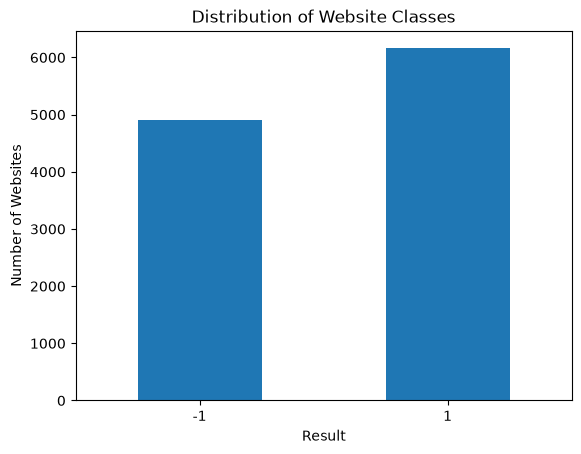

In [3]:
import matplotlib.pyplot as plt

df["Result"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Website Classes")
plt.xlabel("Result")
plt.ylabel("Number of Websites")
plt.xticks(rotation=0)
plt.show()

In [4]:
df.drop(columns="Result").nunique().value_counts()

2    22
3     8
Name: count, dtype: int64

In [5]:
for column in df.drop(columns="Result").columns:
    print(column, ":", sorted(df[column].unique()))

having_IP_Address : [b'-1', b'1']
URL_Length : [b'-1', b'0', b'1']
Shortining_Service : [b'-1', b'1']
having_At_Symbol : [b'-1', b'1']
double_slash_redirecting : [b'-1', b'1']
Prefix_Suffix : [b'-1', b'1']
having_Sub_Domain : [b'-1', b'0', b'1']
SSLfinal_State : [b'-1', b'0', b'1']
Domain_registeration_length : [b'-1', b'1']
Favicon : [b'-1', b'1']
port : [b'-1', b'1']
HTTPS_token : [b'-1', b'1']
Request_URL : [b'-1', b'1']
URL_of_Anchor : [b'-1', b'0', b'1']
Links_in_tags : [b'-1', b'0', b'1']
SFH : [b'-1', b'0', b'1']
Submitting_to_email : [b'-1', b'1']
Abnormal_URL : [b'-1', b'1']
Redirect : [b'0', b'1']
on_mouseover : [b'-1', b'1']
RightClick : [b'-1', b'1']
popUpWidnow : [b'-1', b'1']
Iframe : [b'-1', b'1']
age_of_domain : [b'-1', b'1']
DNSRecord : [b'-1', b'1']
web_traffic : [b'-1', b'0', b'1']
Page_Rank : [b'-1', b'1']
Google_Index : [b'-1', b'1']
Links_pointing_to_page : [b'-1', b'0', b'1']
Statistical_report : [b'-1', b'1']


In [6]:
feature_value_counts = {}

for column in df.drop(columns="Result").columns:
    feature_value_counts[column] = df[column].value_counts().to_dict()

feature_value_counts

{'having_IP_Address': {b'1': 7262, b'-1': 3793},
 'URL_Length': {b'-1': 8960, b'1': 1960, b'0': 135},
 'Shortining_Service': {b'1': 9611, b'-1': 1444},
 'having_At_Symbol': {b'1': 9400, b'-1': 1655},
 'double_slash_redirecting': {b'1': 9626, b'-1': 1429},
 'Prefix_Suffix': {b'-1': 9590, b'1': 1465},
 'having_Sub_Domain': {b'1': 4070, b'0': 3622, b'-1': 3363},
 'SSLfinal_State': {b'1': 6331, b'-1': 3557, b'0': 1167},
 'Domain_registeration_length': {b'-1': 7389, b'1': 3666},
 'Favicon': {b'1': 9002, b'-1': 2053},
 'port': {b'1': 9553, b'-1': 1502},
 'HTTPS_token': {b'1': 9259, b'-1': 1796},
 'Request_URL': {b'1': 6560, b'-1': 4495},
 'URL_of_Anchor': {b'0': 5337, b'-1': 3282, b'1': 2436},
 'Links_in_tags': {b'0': 4449, b'-1': 3956, b'1': 2650},
 'SFH': {b'-1': 8440, b'1': 1854, b'0': 761},
 'Submitting_to_email': {b'1': 9041, b'-1': 2014},
 'Abnormal_URL': {b'1': 9426, b'-1': 1629},
 'Redirect': {b'0': 9776, b'1': 1279},
 'on_mouseover': {b'1': 9740, b'-1': 1315},
 'RightClick': {b'1': 

### EDA Observation: Feature Value Distribution

The frequency analysis shows that the encoded values are not uniformly distributed across the features. Some features are highly concentrated around a single value, while others show a more balanced distribution across two or three possible values.

For example, `RightClick`, `Iframe`, and `Redirect` contain a large proportion of observations belonging to one encoded value, whereas features such as `having_Sub_Domain` have a more distributed representation across their possible values.

This variation in feature distributions will be investigated further to determine whether certain features provide more useful information for phishing website classification.

In [7]:
for column in df.columns:
    if df[column].dtype == "object":
        df[column] = df[column].str.decode("utf-8").astype(int)

df.dtypes.value_counts()

int64    31
Name: count, dtype: int64

In [ ]:
# run the last code in chat and then go further 